In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sc

In [144]:
df = pd.read_csv('Cellphone.csv')

In [145]:
df.head(2)

,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
0,203,2357,10,135.00,5.20,424,8,1.35,16.00,3.00,13.00,8.00,2610,7.40
1,880,1749,10,125.00,4.00,233,2,1.30,4.00,1.00,3.15,0.00,1700,9.90


In [146]:
df = df.drop(columns=['Product_id'])

In [147]:
df.shape

(161, 13)

In [148]:
df.describe()

,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
count,161.00,161.00,161.00,161.00,161.00,161.00,161.00,161.00,161.00,161.00,161.00,161.00,161.00
mean,2215.60,621.47,170.43,5.21,335.06,4.86,1.50,24.50,2.20,10.38,4.50,2842.11,8.92
std,768.19,1546.62,92.89,1.51,134.83,2.44,0.60,28.80,1.61,6.18,4.34,1366.99,2.19
min,614.00,10.00,66.00,1.40,121.00,0.00,0.00,0.00,0.00,0.00,0.00,800.00,5.10
25%,1734.00,37.00,134.10,4.80,233.00,4.00,1.20,8.00,1.00,5.00,0.00,2040.00,7.60
50%,2258.00,106.00,153.00,5.15,294.00,4.00,1.40,16.00,2.00,12.00,5.00,2800.00,8.40
75%,2744.00,382.00,170.00,5.50,428.00,8.00,1.88,32.00,3.00,16.00,8.00,3240.00,9.80
max,4361.00,9807.00,753.00,12.20,806.00,8.00,2.70,128.00,6.00,23.00,20.00,9500.00,18.50


In [149]:
Q1_sale = np.percentile(df['Sale'],25) 
Q3_sale = np.percentile(df['Sale'],75)
Q1_sale

np.float64(37.0)

In [150]:
IQR_sale = Q3_sale - Q1_sale
IQR_sale

np.float64(345.0)

In [151]:
lower_sale = Q1_sale - (1.5*IQR_sale)
upper_sale = Q3_sale + (1.5*IQR_sale)
lower_sale

np.float64(-480.5)

In [152]:
upper_sale

np.float64(899.5)

In [153]:
df = df[df['Sale'].between(lower_sale, upper_sale)]

In [155]:
Q1_we = np.percentile(df['weight'],25)
Q3_we = np.percentile(df['weight'],75)
Q1_we

np.float64(134.0)

In [156]:
IQR = Q3_we - Q1_we
IQR

np.float64(35.0)

In [157]:
lower_we = Q1_we - (1.5*IQR)
upper_we = Q3_we + (1.5*IQR)
lower_we

np.float64(81.5)

In [158]:
upper_we

np.float64(221.5)

In [159]:
df = df[df['weight'].between(lower_we, upper_we)]

In [161]:
Q1_r = np.percentile(df['resoloution'],25)
Q3_r = np.percentile(df['resoloution'],75)

In [162]:
IQR_r = Q3_r - Q1_r
IQR_r

np.float64(0.7000000000000002)

In [163]:
lower_r = Q1_r - (1.5*IQR_r)
upper_r = Q3_r + (1.5*IQR_r)
lower_r

np.float64(3.7499999999999996)

In [164]:
upper_r

np.float64(6.550000000000001)

<Axes: ylabel='Price'>

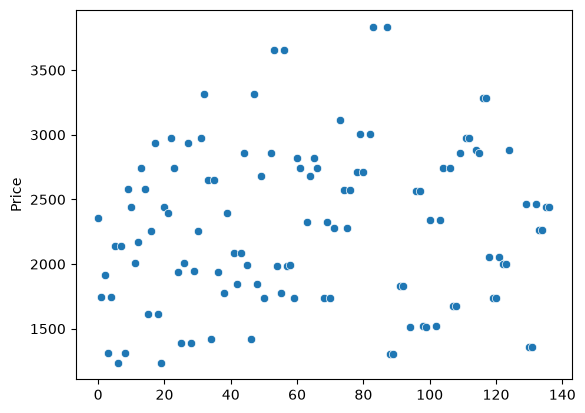

In [202]:
sc.scatterplot(df['Price'])

<Axes: >

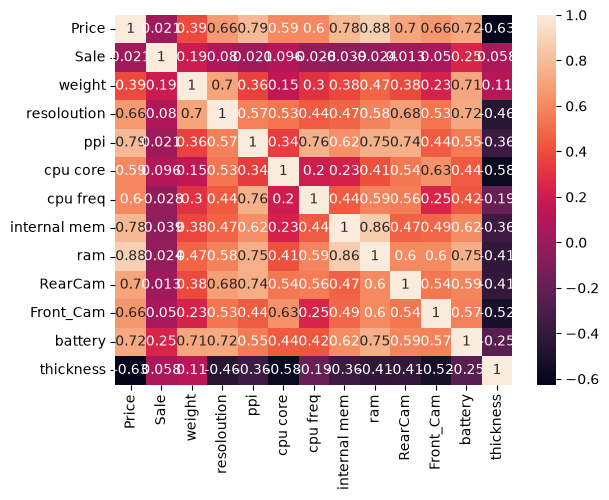

In [203]:
sc.heatmap(df.corr(numeric_only=True),annot=True)

<Axes: xlabel='resoloution'>

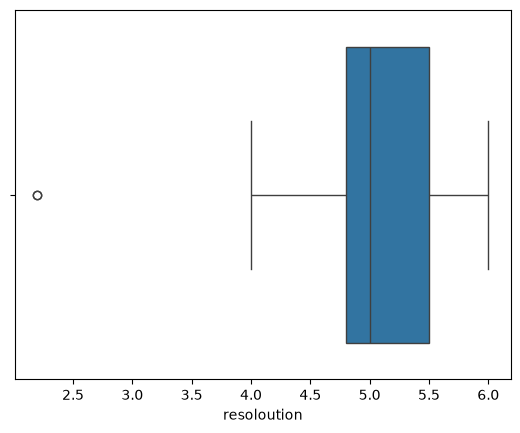

In [165]:
sc.boxplot(x=df['resoloution'])

In [166]:
df = df[df['resoloution'].between(lower_r, upper_r)]

In [168]:
df.columns

Index(['Price', 'Sale', 'weight', 'resoloution', 'ppi', 'cpu core', 'cpu freq',
       'internal mem', 'ram', 'RearCam', 'Front_Cam', 'battery', 'thickness'],
      dtype='str')

In [178]:
df.head(2)

,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
0,2357,10,135.00,5.20,424,8,1.35,16.00,3.00,13.00,8.00,2610,7.40
1,1749,10,125.00,4.00,233,2,1.30,4.00,1.00,3.15,0.00,1700,9.90


In [183]:
X = df.drop('Price',axis =1)
Y = df['Price']

In [184]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [185]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scal = scaler.fit_transform(X_train)
X_test_scal = scaler.transform(X_test)

In [239]:
from sklearn.linear_model import LinearRegression
model = LinearRegression(n_jobs=1
                         )
model.fit(X_train_scal,y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ -15.1 , 59.29,-103.89,..., 11.89, 120.36,-155.66]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2282
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](12,)","[23.8 ,11.73,10.75,..., 3.62, 2.85, 2.17]"


In [240]:
y = model.predict(X_test_scal)

In [241]:
from sklearn.metrics import r2_score

In [242]:
r2_score(y_test,y)

0.8405682656717713

In [243]:
df.head(1)

,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
0,2357,10,135.00,5.20,424,8,1.35,16.00,3.00,13.00,8.00,2610,7.40


In [ ]:
z = [8,80,3.0,300,6,0.75,8,2,11,5,2000,4]


In [194]:
from sklearn.model_selection import cross_val_score

In [197]:
cv = cross_val_score(model,X_train_scal,y_train, cv=5, scoring='r2')

In [198]:
cv

array([0.944808  , 0.89319266, 0.92680652, 0.86205161, 0.76458804])

In [199]:
cv.mean()

np.float64(0.8782893678441672)

In [228]:
from sklearn.model_selection import GridSearchCV

Gcv = GridSearchCV((model),{
    'n_jobs':[1,2,3]
},cv=5,scoring='r2'
)

In [229]:
Gcv.fit(X_train_scal,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearRegression(n_jobs=10)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_jobs': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with higherval

In [230]:
g = Gcv.predict(X_test_scal)

In [231]:
Gcv.cv_results_

{'mean_fit_time': array([0.00537362, 0.00195408, 0.00375152]),
 'std_fit_time': array([0.00194908, 0.00187848, 0.00352885]),
 'mean_score_time': array([0.0026268 , 0.00565629, 0.00262127]),
 'std_score_time': array([0.00094373, 0.00265404, 0.00314995]),
 'param_n_jobs': masked_array(data=[1, 2, 3],
              mask=[False, False, False],
        fill_value=999999),
 'params': [{'n_jobs': 1}, {'n_jobs': 2}, {'n_jobs': 3}],
 'split0_test_score': array([0.944808, 0.944808, 0.944808]),
 'split1_test_score': array([0.89319266, 0.89319266, 0.89319266]),
 'split2_test_score': array([0.92680652, 0.92680652, 0.92680652]),
 'split3_test_score': array([0.86205161, 0.86205161, 0.86205161]),
 'split4_test_score': array([0.76458804, 0.76458804, 0.76458804]),
 'mean_test_score': array([0.87828937, 0.87828937, 0.87828937]),
 'std_test_score': array([0.06354905, 0.06354905, 0.06354905]),
 'rank_test_score': array([1, 1, 1], dtype=int32)}

In [232]:
Gcc = pd.DataFrame(Gcv.cv_results_)

In [233]:
Gcc

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_jobs,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.01,0.00,0.00,0.00,1,{'n_jobs': 1},0.94,0.89,0.93,0.86,0.76,0.88,0.06,1
1,0.00,0.00,0.01,0.00,2,{'n_jobs': 2},0.94,0.89,0.93,0.86,0.76,0.88,0.06,1
2,0.00,0.00,0.00,0.00,3,{'n_jobs': 3},0.94,0.89,0.93,0.86,0.76,0.88,0.06,1
